In [44]:
import pandas as pd

c101 = pd.read_table('solomon_datasets/C101.txt', skiprows=8, index_col=0, sep='\s+', header=None, names=['x', 'y', 'demand', 'ready_time', 'due_date', 'service_time'])
c101 = c101.drop(columns=['demand', 'ready_time', 'due_date', 'service_time'])
c101['x'] = c101['x']/100
c101['y'] = c101['y']/100
print(c101)

        x     y
0    0.40  0.50
1    0.45  0.68
2    0.45  0.70
3    0.42  0.66
4    0.42  0.68
..    ...   ...
96   0.60  0.80
97   0.60  0.85
98   0.58  0.75
99   0.55  0.80
100  0.55  0.85

[101 rows x 2 columns]


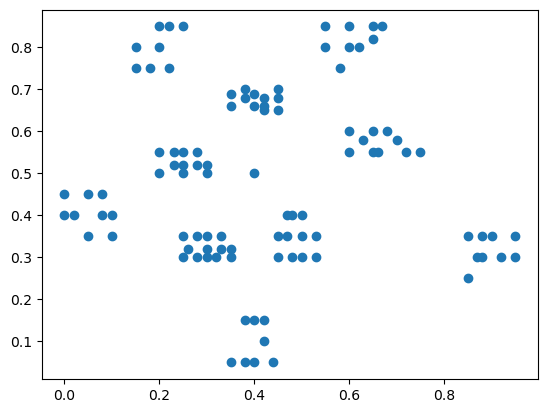

In [45]:
# plot the customer locations on a 1x1 grid
import matplotlib.pyplot as plt
plt.scatter(c101['x'], c101['y'])
plt.show()


In [46]:
def load_and_plot_solomon_dataset(file):
    df = pd.read_table(file, skiprows=8, index_col=0, sep='\s+', header=None, names=['x', 'y', 'demand', 'ready_time', 'due_date', 'service_time'])
    df = df.drop(columns=['demand', 'ready_time', 'due_date', 'service_time'])
    df['x'] = df['x']/100
    df['y'] = df['y']/100
    plt.scatter(df['x'], df['y'])
    plt.show()

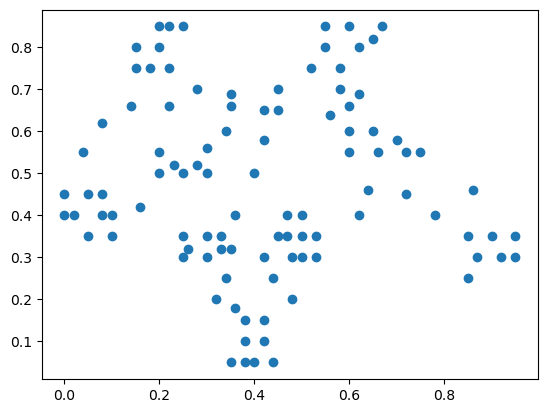

In [51]:
load_and_plot_solomon_dataset('solomon_datasets/C202.txt')

In [95]:
# look into generating problem instances based on the distribution of customers in one of the two Solomon clustered datasets

import numpy as np
import torch
from problems.state_pdtrp import StatePDTRP

filename = 'valsetC1460100.5,txt'

# set seeds for reproducibility
np.random.seed(12345)
torch.manual_seed(12345)

all_nodes_list = []
arrival_times_list = []
service_times_list = []
tours_list = []

x_coords = np.array(c101['x'])
y_coords = np.array(c101['y'])
all_coords = np.column_stack((x_coords, y_coords))

N_TOTAL = 100
E_DOD = 0.5
TIME_HORIZON = 460
N_SAMPLES = 1280

exp_n_static = N_TOTAL * E_DOD

for i in range(N_SAMPLES):

    # Step 1: sample N_TOTAL nodes ranfomly from the Solomon dataset (do not sample the depot)
    idx = np.random.choice(range(1, len(all_coords)), N_TOTAL, replace=False)
    sampled_coords = all_coords[idx].squeeze()
    coords_i = np.concatenate([all_coords[0].reshape(1,2), sampled_coords], axis=0)

    # Step 2: sample the number of dynamic nodes 

    p_lambda = (N_TOTAL - exp_n_static) / TIME_HORIZON
    n_dyna = np.random.poisson(p_lambda * TIME_HORIZON)

    n_static = N_TOTAL - n_dyna

    # The first index of coords_i is the depot, the next n_staic indexes of coords_i are the static nodes and the rest are the dynamic nodes

    # Step 3: Generate the arrival times for the dynamic nodes
    arrival_times = np.sort(np.random.uniform(0.1, TIME_HORIZON, size=(n_dyna))).squeeze() 
    # prepend n_static + 1 zeros to the arrival times to account for the depot and the static nodes
    arrival_times = np.concatenate([np.zeros(n_static + 1), arrival_times], axis=0)

    # Step 4: Generate the service times for all nodes
    service_times = np.random.uniform(0.1, 10, size=(N_TOTAL)).squeeze()
    # prepend a zero to the service times to account for the depot
    service_times = np.concatenate([np.zeros(1), service_times], axis=0)

    tour = [0]
    # Step 7: Solve the problem with a nearest neighbor heuristic
    state = StatePDTRP.initialize(torch.tensor(coords_i).unsqueeze(0), torch.tensor(service_times).unsqueeze(0), torch.tensor(arrival_times).unsqueeze(0))
    selected = torch.zeros((1, 1), dtype=torch.int64)
    while not state.all_finished():
        visited_mask = state.get_visited()
        arrival_mask = state.get_not_arrived()
        mask = torch.logical_or(visited_mask, arrival_mask)
        distances_to_current = (torch.tensor(coords_i).unsqueeze(0) - torch.tensor(coords_i).unsqueeze(0)[0, selected]).norm(p=2, dim=-1)

        distances_to_current[mask[:,0,:]] = float('inf')

        selected = torch.argmin(distances_to_current, dim=1)

        state = state.update(selected)
        tour.append(selected.item())


    all_nodes_list += [coords_i]
    arrival_times_list += [arrival_times]
    service_times_list += [service_times]
    tours_list += [tour]

with open("data/pdtrp/" + filename, "w") as f:
    for i in range(N_SAMPLES):
        f.write( " ".join( str(x)+str(" ")+str(y) for x,y in all_nodes_list[i]))
        f.write( str(" ") + str("arrival_times" + str(" ")))
        f.write( str(" ").join(str(x) for x in arrival_times_list[i]))
        f.write( str(" ") + str("service_times" + str(" ")))
        f.write( str(" ").join(str(x) for x in service_times_list[i]))
        f.write( str(" ") + str('output') + str(" ") )
        f.write( str(" ").join(str(node_idx+1) for node_idx in tours_list[i]) )
        f.write( str(" ") + str(tours_list[i][0]+1) + str(" ") )
        f.write( "\n" )


In [100]:
# load in the RC101 dataset

import pandas as pd

rc101 = pd.read_table('solomon_datasets/RC201.txt', skiprows=8, index_col=0, sep='\s+', header=None, names=['x', 'y', 'demand', 'ready_time', 'due_date', 'service_time'])
rc101 = rc101.drop(columns=['demand', 'ready_time', 'due_date', 'service_time'])
rc101['x'] = rc101['x']/100
rc101['y'] = rc101['y']/100
print(rc101)

        x     y
0    0.40  0.50
1    0.25  0.85
2    0.22  0.75
3    0.22  0.85
4    0.20  0.80
..    ...   ...
96   0.55  0.54
97   0.04  0.18
98   0.26  0.52
99   0.26  0.35
100  0.31  0.67

[101 rows x 2 columns]


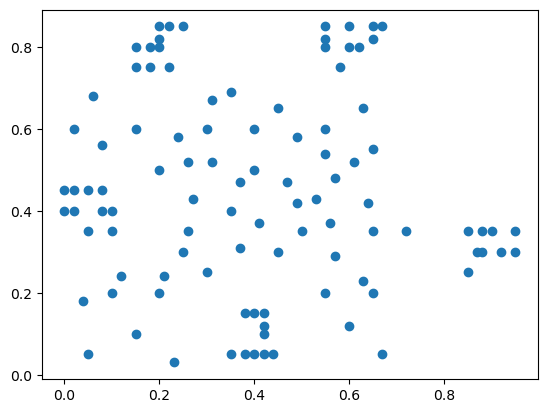

In [102]:
# plot the customer locations on a 1x1 grid
import matplotlib.pyplot as plt
plt.scatter(rc101['x'], rc101['y'])
plt.show()

In [90]:
def plot_tsp_tour(p, nodes_coords, tour_nodes, title):
    sorted_nodes = [nodes_coords[i] for i in tour_nodes]
    p.annotate('Start', (sorted_nodes[0][0], sorted_nodes[0][1]))
    # Anotate nodes with their index in nodes_coords
    for i, j in enumerate(tour_nodes):
        p.annotate(j, (sorted_nodes[i][0], sorted_nodes[i][1]))
    for i in range(len(sorted_nodes)):
        start_pos = sorted_nodes[i]
        next_node_id = (i + 1) % len(sorted_nodes)
        next_node = sorted_nodes[next_node_id]
        p.plot(start_pos[0], start_pos[1], 'bo')
        p.annotate("",
                xy=start_pos, xycoords='data',
                xytext=next_node, textcoords='data',
                arrowprops=dict(arrowstyle="<-",
                                connectionstyle="arc3"))

    p.set_title(title)

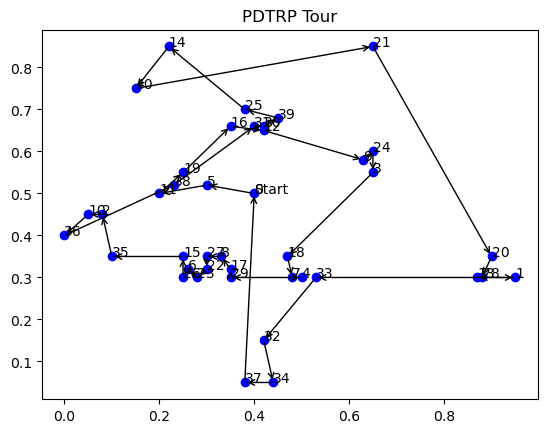

In [91]:
import matplotlib.pyplot as plt

f = plt.figure()
p = f.add_subplot(111)

plot_tsp_tour(p, all_nodes_list[0], tours_list[0], "PDTRP Tour")